In [59]:
using Plots

# Question 1

Equation 2.73 from @turcotteGeodynamics2014

**Function**: pressure (p) as a function of radius (r)

- G = universal gravitational constant
- ρc = core density 
- b = core thickness
- ρm = mantle density 
- a - b = mantle thickness

In [60]:
## function: pressure (p) as a function of radius (r)
function p(r, a, b, ρc, ρm; G=6.6743e-11)
    if r >= b # mantle: b ≤ r ≤ a
        return (4/3) * π * ρm * G * b^3 * (ρc - ρm) * (1/r - 1/a) +
            (2/3) * π * G * ρm^2 * (a^2 - r^2)
    else # core: 0 ≤ r ≤ b
        return (2/3) * π * G * ρc^2 * (b^2 - r^2) +
            (2/3) * π * G * ρm^2 * (a^2 - b^2) +
            (4/3) * π * ρm * G * b^3 * (ρc - ρm) * (1/b - 1/a)
    end
end;

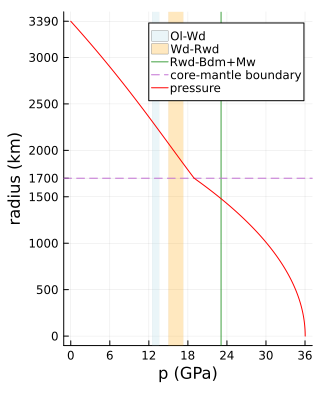

In [61]:
a = 3390e3 # total radius of mars; m
b = 1700e3 # radius of mars' mantle; m

ρc = 6500 # density of mars' core; kg/m3
ρm = 3500 # density of mars' mantle; kg/m3

vspan([12.5, 13.6], color=:lightblue, alpha=0.25, label="Ol-Wd")
vspan!([15, 17.3], color=:orange, alpha=0.25, label="Wd-Rwd")
vline!([23.1], color=:green, alpha=0.75, label="Rwd-Bdm+Mw")

hline!([b/1e3], ls=:dash, label="core-mantle boundary")

plot!(r -> p(r, a, b, ρc, ρm) / 1e9, # convert to GPa
    r -> r / 1e3, # convert to km
    0, a, # range to calc p(r)
    xlabel="p (GPa)", ylabel="radius (km)", label="pressure", legend=true, color=:red, size = (325, 400))
yticks!(vcat(0:500:(a/1e3), b/1e3, a/1e3))
xticks!(0:6:36)

In [62]:
savefig("attachments/q1-pressure_v_depth.pdf")

"/Users/nathalieredick/repos/washu/courses/eeps-5534/hw/hw3/attachments/q1-pressure_v_depth.pdf"